## Across a 4-week period, how does this barber's workload vary by day and time, and where is his schedule over or under-booked?

### Sub Questions:
1. Demand pattern - Which days are busiest/quietest? Does demand concentrate in a particular time block?
2. Service mix & duration trend - Which services does the barber do most? Which take longest? Is there a difference in duration between walk-ins and appointments?
3. Wait time - When do clients wait longest? Does wait time correlate with how busy that day/block is?
4. Capacity & idle time - Roughly how many service minutes is the barber delivering per day vs. a fixed shift length? Which days/blocks show the most idle capacity vs. overload?
5. Trend over the 4 weeks - Is total weekly volume rising or falling?

## Step 1: Setup and Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('barber_appointments.csv')

In [3]:
df.head()

,date,day_of_week,time_block,service_type,duration_min,wait_time_min,booking_type
0,2026-08-04,Tuesday,Evening (4-7),Haircut,38,9,Walk-in
1,2026-08-04,Tuesday,Evening (4-7),Kids Cut,25,8,Walk-in
2,2026-08-04,Tuesday,Afternoon (12-4),Beard Trim,18,7,Appointment
3,2026-08-04,Tuesday,Evening (4-7),Haircut + Beard,53,9,Walk-in
4,2026-08-04,Tuesday,Afternoon (12-4),Beard Trim,17,8,Appointment


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 237 entries, 0 to 236
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   date           237 non-null    object
 1   day_of_week    237 non-null    object
 2   time_block     237 non-null    object
 3   service_type   237 non-null    object
 4   duration_min   237 non-null    int64 
 5   wait_time_min  237 non-null    int64 
 6   booking_type   237 non-null    object
dtypes: int64(2), object(5)
memory usage: 13.1+ KB


In [5]:
df.describe() # Only checks the continous numerical values of the columns (int64)

,duration_min,wait_time_min
count,237.000000,237.000000
mean,30.628692,6.700422
std,12.373996,3.856389
min,12.000000,0.000000
25%,21.000000,4.000000
50%,30.000000,7.000000
75%,38.000000,9.000000
max,77.000000,17.000000


**Observations (from `df.info()` and `df.describe()`)**
- The dataset has 237 rows and 7 columns.
- Service duration: mean 30.6 mins, median 30, minimum 12, maximum 77.
- Wait time: mean 6.7 mins, median 7, minimum 0, maximum 17.

## Step 2: Data Cleaning and Validation
Check for missing values, data types, duplicates and inconsistent categories; convert `date` to datetime; confirm the date range is complete; and sanity-check durations by service type.

In [6]:
df.isnull().sum()

date             0
day_of_week      0
time_block       0
service_type     0
duration_min     0
wait_time_min    0
booking_type     0
dtype: int64

In [7]:
df.dtypes

date             object
day_of_week      object
time_block       object
service_type     object
duration_min      int64
wait_time_min     int64
booking_type     object
dtype: object

In [8]:
print('Duplicate rows:', df.duplicated().sum())
df[df.duplicated(keep=False)]

Duplicate rows: 2


,date,day_of_week,time_block,service_type,duration_min,wait_time_min,booking_type
95,2026-08-15,Saturday,Afternoon (12-4),Haircut,33,8,Appointment
99,2026-08-15,Saturday,Afternoon (12-4),Haircut,33,8,Appointment
206,2026-08-28,Friday,Evening (4-7),Haircut,31,4,Appointment
208,2026-08-28,Friday,Evening (4-7),Haircut,31,4,Appointment


**Observations (missing values, data types, duplicates)**
- `df.isnull().sum()` shows 0 missing values in every column.
- `date` is read in as text (`object`) and will be converted to datetime later. The two minute columns are integers and the other columns are text.
- `df.duplicated().sum()` shows 2 rows that repeat an earlier row exactly across all 7 columns. The data has no visit ID column, so these rows are left in - just in case they are of coincidence.

In [9]:
# df['booking_type'].value_counts()

for col in ['day_of_week', 'time_block', 'service_type', 'booking_type']:
    print(f"--- {col} ---")
    print(df[col].value_counts())
    print() # Print a space

--- day_of_week ---
day_of_week
Saturday     52
Friday       47
Sunday       40
Thursday     36
Wednesday    33
Tuesday      29
Name: count, dtype: int64

--- time_block ---
time_block
Evening (4-7)       88
Afternoon (12-4)    78
Morning (9-12)      71
Name: count, dtype: int64

--- service_type ---
service_type
Haircut            110
Haircut + Beard     46
Beard Trim          42
Kids Cut            16
Shave               15
Colour/Chemical      8
Name: count, dtype: int64

--- booking_type ---
booking_type
Walk-in        119
Appointment    118
Name: count, dtype: int64



**Observations (category counts)**
- `day_of_week`: Saturday 52, Friday 47, Sunday 40, Thursday 36, Wednesday 33, Tuesday 29. Mondays are days off.
- `time_block`: Evening 88, Afternoon 78, Morning 71.
- `service_type`: Haircut 110, Haircut + Beard 46, Beard Trim 42, Kids Cut 16, Shave 15, Colour/Chemical 8.
- `booking_type`: Walk-in 119, Appointment 118.

In [10]:
# Converting object 'date' to datetime (better for organisation later):

df['date'] = pd.to_datetime(df['date'])
df.dtypes   # Confirmation

date             datetime64[ns]
day_of_week              object
time_block               object
service_type             object
duration_min              int64
wait_time_min             int64
booking_type             object
dtype: object

In [11]:
df['date'].min(), df['date'].max()

(Timestamp('2026-08-04 00:00:00'), Timestamp('2026-08-30 00:00:00'))

In [12]:
df['date'].nunique()

24

In [13]:
sorted(df['date'].dt.day_name().unique())

['Friday', 'Saturday', 'Sunday', 'Thursday', 'Tuesday', 'Wednesday']

In [14]:
expected_dates = pd.date_range(start='2026-08-04', end='2026-08-30')
actual_dates = pd.to_datetime(df['date'].unique()) # Grabs all unique dates from the dataframe

missing_dates = expected_dates.difference(actual_dates)
print(missing_dates)
print(missing_dates.day_name().tolist())

DatetimeIndex(['2026-08-10', '2026-08-17', '2026-08-24'], dtype='datetime64[ns]', freq=None)
['Monday', 'Monday', 'Monday']


**Observations (date range)**
- Dates run from 2026-08-04 to 2026-08-30, and `df['date'].nunique()` shows visits on 24 distinct dates.
- The weekdays present in the data are Tuesday to Sunday.
- The only dates in that range with no visits are 10, 17 and 24 Aug, and all three are Mondays (printed above).

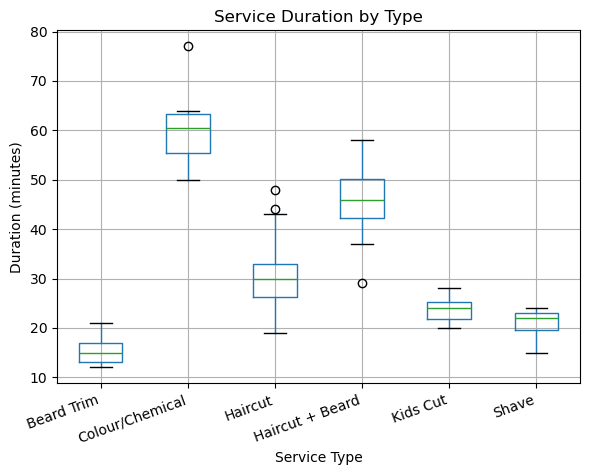

In [15]:
ax = df.boxplot(column='duration_min', by='service_type', figsize=(6, 5))

plt.title('Service Duration by Type')
plt.suptitle('')
plt.xlabel('Service Type')
plt.ylabel('Duration (minutes)')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

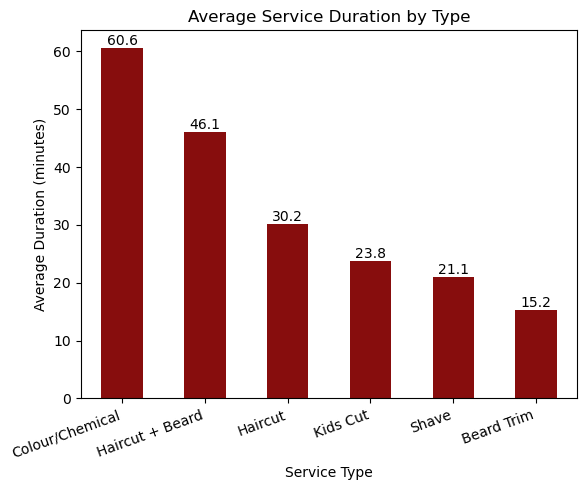

In [16]:
avg_duration = df.groupby('service_type')['duration_min'].mean().sort_values(ascending=False)

ax = avg_duration.plot(kind='bar', figsize=(6, 5), color='#870D0D')

plt.title('Average Service Duration by Type')
plt.xlabel('Service Type')
plt.ylabel('Average Duration (minutes)')
plt.xticks(rotation=20, ha='right')
ax.bar_label(ax.containers[0], fmt='%.1f')   # prints the value on each bar
plt.tight_layout()
plt.show()

In [17]:
df.groupby('service_type')['duration_min'].describe()

,count,mean,std,min,25%,50%,75%,max
service_type,,,,,,,,
Beard Trim,42.0,15.214286,2.353365,12.0,13.00,15.0,17.00,21.0
Colour/Chemical,8.0,60.625000,8.175530,50.0,55.50,60.5,63.25,77.0
Haircut,110.0,30.154545,5.464122,19.0,26.25,30.0,33.00,48.0
Haircut + Beard,46.0,46.130435,5.965116,29.0,42.25,46.0,50.25,58.0
Kids Cut,16.0,23.750000,2.645751,20.0,21.75,24.0,25.25,28.0
Shave,15.0,21.066667,2.604026,15.0,19.50,22.0,23.00,24.0


**Observations (duration by service type, from the boxplot and table above)**
- Average duration, longest to shortest: Colour/Chemical 60.6 min, Haircut + Beard 46.1, Haircut 30.2, Kids Cut 23.8, Shave 21.1, Beard Trim 15.2.
- Standard deviation is smallest for Beard Trim (2.4 min) and largest for Colour/Chemical (8.2 min).
- So the Colour/Chemical service varies in time the most, whereas Beard Trims are typically similar durations.

In [18]:
beard = df[df['service_type'] == 'Beard Trim']['booking_type']
pd.concat([beard.value_counts(), beard.value_counts(normalize=True).round(3)],
          axis=1, keys=['count', 'share'])

,count,share
booking_type,,
Appointment,26,0.619
Walk-in,16,0.381


**Observations (Beard Trim booking type)**
- 26 of 42 Beard Trims (61.9%) were appointments and 16 (38.1%) were walk-ins.

## Step 3: Feature Engineering
Create ordered day and time-block categories, a weekend flag and a week number (Weeks 1-4) to support the analysis that follows.

In [19]:
day_order = ['Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

df['day_of_week'] = pd.Categorical(
    df['day_of_week'],
    categories=day_order,
    ordered=True
)

# Just to order the days when calling 'day_of_week'

In [20]:
block_order = ['Morning (9-12)', 'Afternoon (12-4)', 'Evening (4-7)']
df['time_block'] = pd.Categorical(
    df['time_block'],
    categories=block_order,
    ordered=True
)

In [21]:
df['is_weekend'] = df['day_of_week'].isin(['Saturday', 'Sunday'])

In [22]:
# Creating a new column as "week_number" and grouping the dates to the corresponding week.
start_date = df['date'].min()
df['week_number'] = ((df['date'] - start_date).dt.days // 7) + 1
df['week_number'].value_counts().sort_index()

week_number
1    60
2    57
3    62
4    58
Name: count, dtype: int64

In [23]:
df.dtypes
df[['date', 'day_of_week', 'week_number', 'is_weekend', 'time_block']].head()

,date,day_of_week,week_number,is_weekend,time_block
0,2026-08-04,Tuesday,1,False,Evening (4-7)
1,2026-08-04,Tuesday,1,False,Evening (4-7)
2,2026-08-04,Tuesday,1,False,Afternoon (12-4)
3,2026-08-04,Tuesday,1,False,Evening (4-7)
4,2026-08-04,Tuesday,1,False,Afternoon (12-4)


## Step 4: Univariate EDA
Visit volume by day and week, and the distribution of each individual column variable.

In [24]:
visits_pivot = df.pivot_table(
    index='week_number',
    columns='day_of_week',
    values='date',
    aggfunc='count',
    fill_value=0,
    observed=False
)
visits_pivot

day_of_week,Tuesday,Wednesday,Thursday,Friday,Saturday,Sunday
week_number,,,,,,
1,7,8,9,13,14,9
2,7,8,8,11,12,11
3,8,8,10,11,14,11
4,7,9,9,12,12,9


**Observations (visits per weekday in each week, from the table above)**
- Saturday has the most visits in weeks 1 to 3 (14, 12, 14) and ties with Friday in week 4 (12 each).
- Tuesday has the fewest visits in weeks 1, 2 and 4 (7 each) and ties with Wednesday in week 3 (8 each).

In [25]:
visits_pivot.sum()

day_of_week
Tuesday      29
Wednesday    33
Thursday     36
Friday       47
Saturday     52
Sunday       40
dtype: int64

In [26]:
for day in df['day_of_week'].unique():
    print(f"---{day}---")
    print(df[df['day_of_week'] == day]['duration_min'].sum()/60/4)

---Tuesday---
3.845833333333333
---Wednesday---
3.995833333333333
---Thursday---
4.641666666666667
---Friday---
6.183333333333334
---Saturday---
6.458333333333333
---Sunday---
5.120833333333334


**Observations (total visits and average service hours per day)**
- Total visits over the 4 weeks: Saturday 52, Friday 47, Sunday 40, Thursday 36, Wednesday 33, Tuesday 29.
- Average booked service time per day (total service hours for that weekday divided by 4 weeks): Saturday 6.5 h, Friday 6.2 h, Sunday 5.1 h, Thursday 4.6 h, Wednesday 4.0 h, Tuesday 3.8 h.

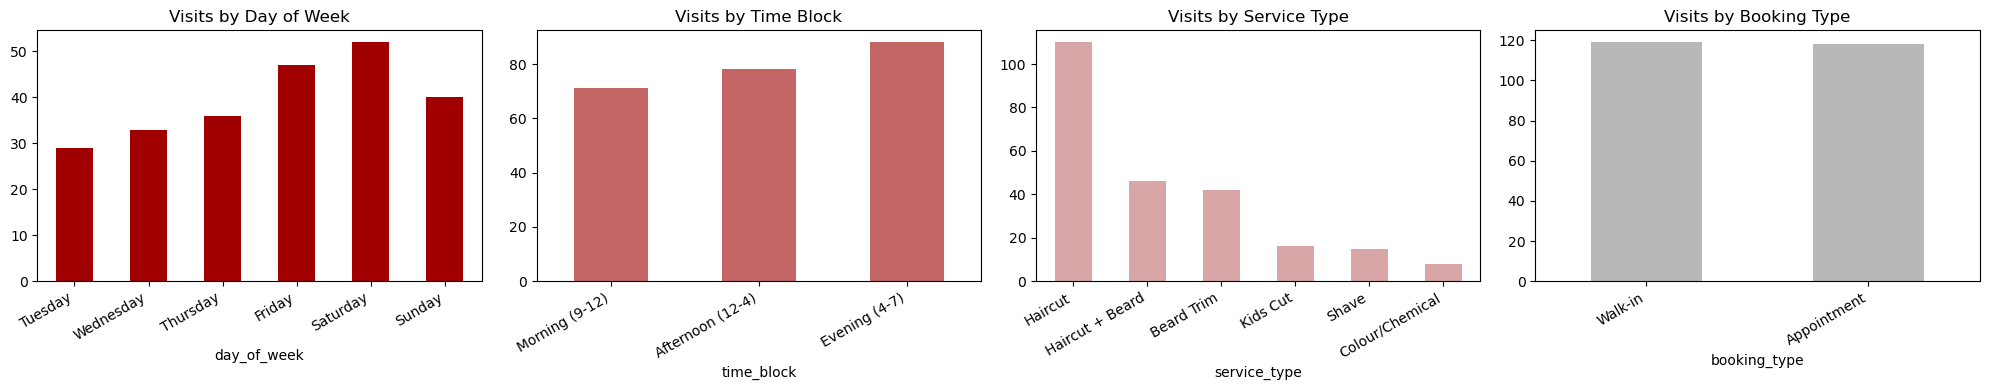

In [27]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

df['day_of_week'].value_counts().sort_index().plot(kind='bar', ax=axes[0], color='#A00000')
axes[0].set_title('Visits by Day of Week')

df['time_block'].value_counts().sort_index().plot(kind='bar', ax=axes[1], color='#C46666')
axes[1].set_title('Visits by Time Block')

df['service_type'].value_counts().plot(kind='bar', ax=axes[2], color='#D8A6A6')
axes[2].set_title('Visits by Service Type')

df['booking_type'].value_counts().plot(kind='bar', ax=axes[3], color='#B8B8B8')
axes[3].set_title('Visits by Booking Type')

for ax in axes:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha='right')

plt.tight_layout()
plt.show()

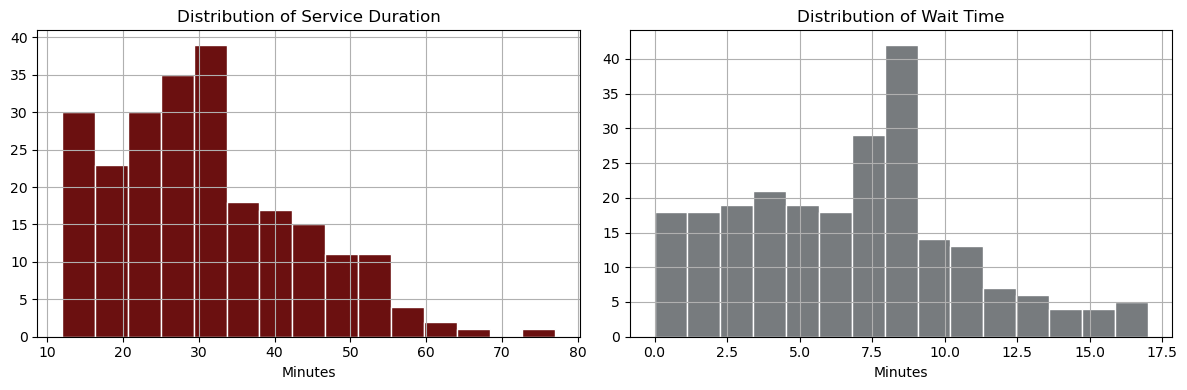

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

df['duration_min'].hist(bins=15, ax=axes[0], color='#6B1010', edgecolor='white')
axes[0].set_title('Distribution of Service Duration')
axes[0].set_xlabel('Minutes')

df['wait_time_min'].hist(bins=15, ax=axes[1], color='#777B7E', edgecolor='white')
axes[1].set_title('Distribution of Wait Time')
axes[1].set_xlabel('Minutes')

plt.tight_layout()
plt.show()

**Observations (distributions)**
- The bar charts plot the same visit counts listed in Step 2.
- Duration: the middle 50% of services lasted between 21 and 38 min (quartiles from `df.describe()` in Step 1).
- Wait time: the middle 50% of visits waited between 4 and 9 min, with a maximum of 17 min (from `df.describe()` in Step 1).

## Step 5: Bivariate / Grouped EDA
Compare variables against each other: duration by service type, wait time by day and time block, and duration by booking type.

In [29]:
df.groupby('service_type', observed=True)['duration_min'].agg(['mean', 'median', 'count']).sort_values('mean', ascending=False)

,mean,median,count
service_type,,,
Colour/Chemical,60.625000,60.5,8
Haircut + Beard,46.130435,46.0,46
Haircut,30.154545,30.0,110
Kids Cut,23.750000,24.0,16
Shave,21.066667,22.0,15
Beard Trim,15.214286,15.0,42


**Observations (mean, median and count by service type)**
- For every service type the mean and median are within 1 minute of each other (e.g. Haircut 30.2 / 30.0, Colour/Chemical 60.6 / 60.5, Shave 21.1 / 22.0).

day_of_week
Tuesday      6.62
Wednesday    5.79
Thursday     6.92
Friday       6.15
Saturday     7.75
Sunday       6.60
Name: wait_time_min, dtype: float64


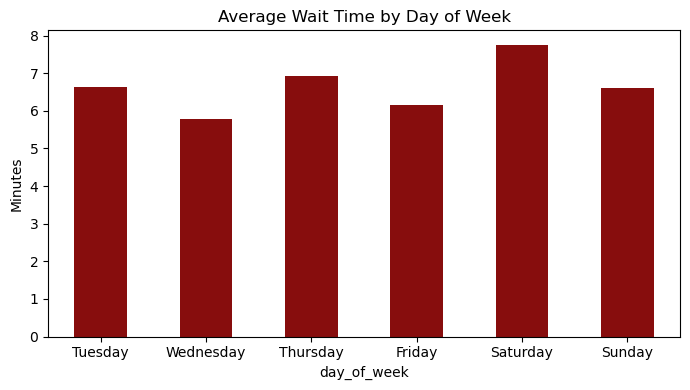

In [30]:
wait_by_day = df.groupby('day_of_week', observed=True)['wait_time_min'].mean()
print(wait_by_day.round(2))

wait_by_day.plot(kind='bar', figsize=(7,4), color='#870D0D')
plt.title('Average Wait Time by Day of Week')
plt.ylabel('Minutes')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

time_block
Morning (9-12)      5.83
Afternoon (12-4)    6.24
Evening (4-7)       7.81
Name: wait_time_min, dtype: float64


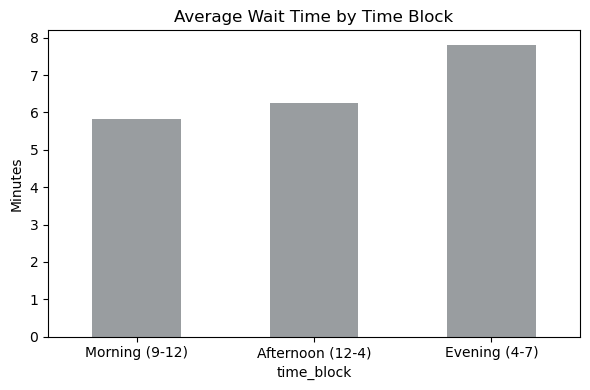

In [31]:
wait_by_block = df.groupby('time_block', observed=True)['wait_time_min'].mean()
print(wait_by_block.round(2))

wait_by_block.plot(kind='bar', figsize=(6,4), color='#999DA0')
plt.title('Average Wait Time by Time Block')
plt.ylabel('Minutes')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

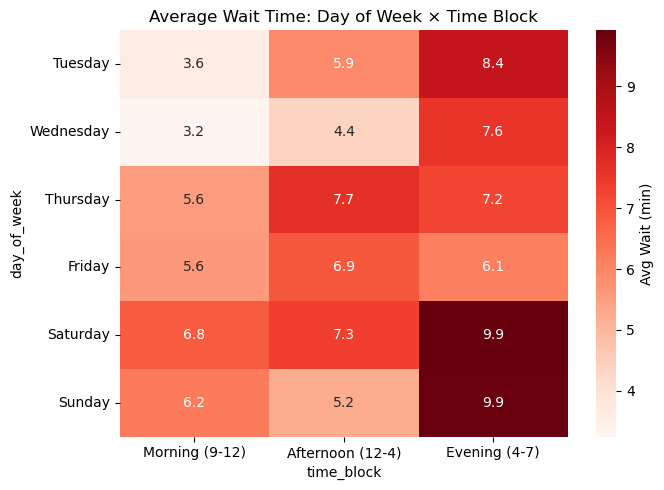

In [32]:
heat_data = df.pivot_table(
    index='day_of_week',
    columns='time_block',
    values='wait_time_min',
    aggfunc='mean',
    observed=False
)

plt.figure(figsize=(7, 5))
sns.heatmap(heat_data, annot=True, fmt='.1f', cmap='Reds', cbar_kws={'label': 'Avg Wait (min)'})
plt.title('Average Wait Time: Day of Week × Time Block')
plt.tight_layout()
plt.show()

**Observations (wait time)**
- By day: Tuesday 6.62 min, Wednesday 5.79, Thursday 6.92, Friday 6.15, Saturday 7.75, Sunday 6.60.
- By time block: Morning 5.83 min, Afternoon 6.24, Evening 7.81.
- In the day x time block heatmap, the highest averages are Saturday evening and Sunday evening (9.9 min each) and the lowest is Wednesday morning (3.2 min).
- The evening block has the highest average wait on Tuesday, Wednesday, Saturday and Sunday. On Thursday and Friday the afternoon block is highest (7.7 and 6.9 min).

In [33]:
df.groupby('booking_type')['duration_min'].mean()

booking_type
Appointment    29.338983
Walk-in        31.907563
Name: duration_min, dtype: float64

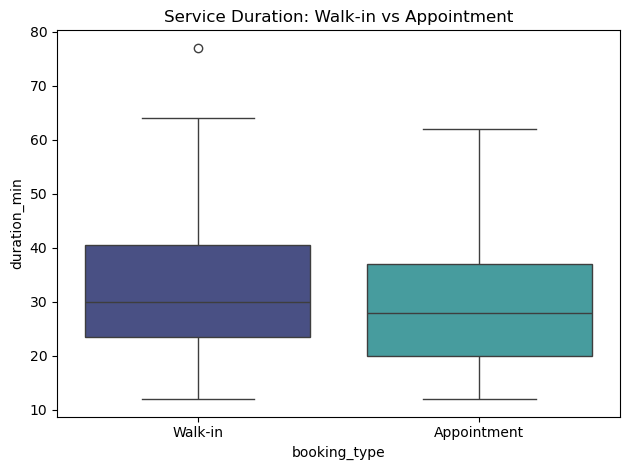

In [34]:
sns.boxplot(data=df, x='booking_type', y='duration_min', hue='booking_type', palette='mako', legend=False)
plt.title('Service Duration: Walk-in vs Appointment')
plt.tight_layout()
plt.show()

**Observations (duration by booking type)**
- Average duration is 29.3 min for appointments and 31.9 min for walk-ins, a difference of 2.6 min.

## Step 6: Capacity and Idle-Time Analysis
Comparing booked service minutes with available minutes (utilisation = booked service minutes / full capacity).

**Assumptions:** an 8-hour (480-minute) working day - full capacity; time block capacities of 180 (Morning), 240 (Afternoon) and 180 (Evening) minutes; idle minutes = full capacity minus booked service minutes, so any break or admin time counts as idle.

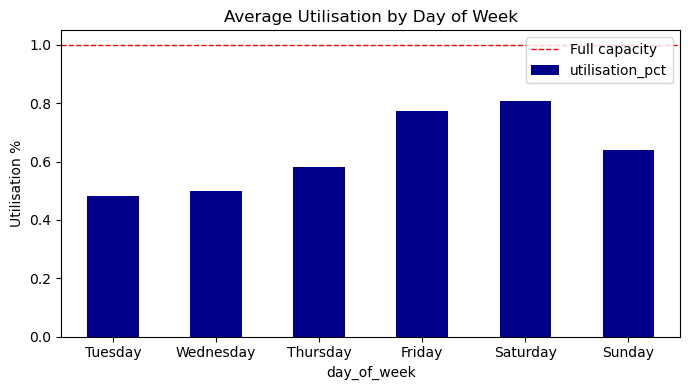

In [35]:
Shift_min = 480  # 8 hour day assumption (60x8)

daily = df.groupby('date', as_index=False)['duration_min'].sum() # 24 buckets of dates
daily.columns = ['date', 'total_booked_min'] # renaming the column to total_booked_min
daily['idle_min'] = Shift_min - daily['total_booked_min'] # Creating new column - idle_min.
daily['utilisation_pct'] = daily['total_booked_min'] / Shift_min # Creating new column - utilisation_pct

daily['day_of_week'] = pd.Categorical(daily['date'].dt.day_name(),
                                      categories=day_order,
                                      ordered=True
                                     )

util_by_day = daily.groupby('day_of_week', observed=True)['utilisation_pct'].mean()
util_by_day.plot(kind='bar', figsize=(7,4), color='#00008B')
plt.axhline(1.0, color='red', linestyle='--', linewidth=1, label='Full capacity')
plt.title('Average Utilisation by Day of Week')
plt.ylabel('Utilisation %')
plt.xticks(rotation=0)
plt.legend()
plt.tight_layout()
plt.show()

In [36]:
util_table = daily.groupby('day_of_week', observed=True).agg(
    avg_booked_min=('total_booked_min', 'mean'),
    avg_idle_min=('idle_min', 'mean'),
    avg_utilisation_pct=('utilisation_pct', lambda a: a.mean() * 100),
    total_idle_hrs=('idle_min', lambda a: a.sum() / 60)
).round(1)
util_table

,avg_booked_min,avg_idle_min,avg_utilisation_pct,total_idle_hrs
day_of_week,,,,
Tuesday,230.8,249.2,48.1,16.6
Wednesday,239.8,240.2,49.9,16.0
Thursday,278.5,201.5,58.0,13.4
Friday,371.0,109.0,77.3,7.3
Saturday,387.5,92.5,80.7,6.2
Sunday,307.2,172.8,64.0,11.5


In [37]:
print(f"Overall average utilisation: {daily['utilisation_pct'].mean():.0%}")
print(f"Total idle time: {daily['idle_min'].sum() / 60:.0f} hours over {len(daily)} open days")
print(f"Tue-Thu idle time: {util_table.loc[['Tuesday', 'Wednesday', 'Thursday'], 'total_idle_hrs'].sum():.0f} hours")
print(f"Days of 100% utilisation: {(daily['utilisation_pct'] == 1).sum()}")
daily.loc[daily['utilisation_pct'].idxmax(), ['date', 'total_booked_min', 'utilisation_pct']]

Overall average utilisation: 63%
Total idle time: 71 hours over 24 open days
Tue-Thu idle time: 46 hours
Days of 100% utilisation: 0


date                2026-08-07 00:00:00
total_booked_min                    435
utilisation_pct                 0.90625
Name: 3, dtype: object

**Observations (daily utilisation)**
- Average utilisation by day: Tuesday 48.1%, Wednesday 49.9%, Thursday 58.0%, Friday 77.3%, Saturday 80.7%, Sunday 64.0%. The overall average is 63%.
- Total idle time is 71 hours over the 24 open days, of which 46 hours fall on Tuesday to Thursday.
- No day with 100% utilisation. The highest single day is Friday 7 Aug, with 435 booked minutes (90.6%).

**Time-Block Utilisation.** Each time-blocks capacity is its length in minutes (Morning 180, Afternoon 240, Evening 180). The heatmap shows the average booked service minutes per block over the 4 weeks as a share of that capacity. Visits are grouped by their recorded `time_block`.

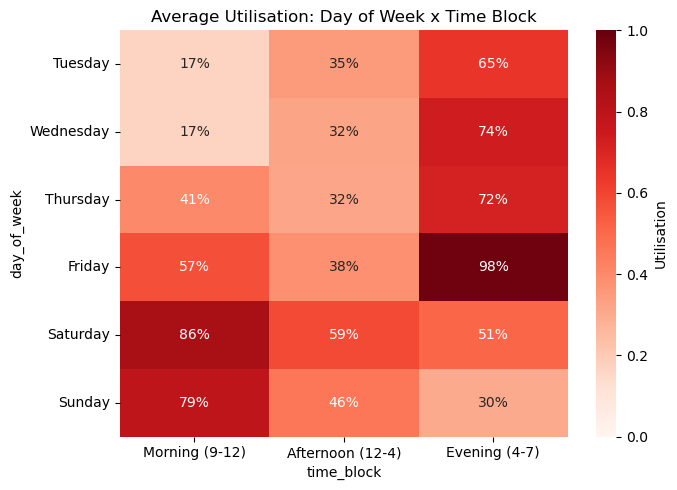

In [38]:
capacity = {'Morning (9-12)': 180, 'Afternoon (12-4)': 240, 'Evening (4-7)': 180}
mins = df.pivot_table(index='day_of_week', columns='time_block',
                      values='duration_min', aggfunc='sum', observed=False) / 4
block_util = mins / pd.Series(capacity)

plt.figure(figsize=(7, 5))
sns.heatmap(block_util, annot=True, fmt='.0%', cmap='Reds', vmin=0, vmax=1,
            cbar_kws={'label': 'Utilisation'})
plt.title('Average Utilisation: Day of Week x Time Block')
plt.tight_layout()
plt.show()

In [39]:
slots = df.groupby(['date', 'time_block'], observed=True)['duration_min'].sum().reset_index()
slots['capacity_min'] = slots['time_block'].map(capacity).astype(int)
slots['utilisation_pct'] = (slots['duration_min'] / slots['capacity_min'] * 100).round(1)

total_slots = df['date'].nunique() * df['time_block'].nunique()   # 24 days x 3 blocks = 72
print(f"{(slots['utilisation_pct'] > 100).sum()} of {total_slots} day-and-block slots went over capacity")
slots.sort_values('utilisation_pct', ascending=False).head()

10 of 72 day-and-block slots went over capacity


,date,time_block,duration_min,capacity_min,utilisation_pct
63,2026-08-28,Evening (4-7),239,180,132.8
29,2026-08-14,Evening (4-7),227,180,126.1
14,2026-08-08,Evening (4-7),216,180,120.0
9,2026-08-07,Morning (9-12),215,180,119.4
58,2026-08-26,Evening (4-7),211,180,117.2


**Observations (block-level utilisation)**
- The highest cell is Friday evening (98%). The lowest are Tuesday and Wednesday morning (17% each).
- On Tuesday to Friday the evening block has the highest utilisation of the three blocks (65%, 74%, 72% and 98%). On Saturday and Sunday the morning block does (86% and 79%).
- Sunday evening is 30%.
- 10 of the 72 day-and-block slots had more booked service minutes than their capacity. This means services were continued beyond they limit of the blocks capacity (overtime).
- The highest was Friday 28 Aug evening at 133% (239 minutes in a 180-minute block).

## Step 7: Trend Over the 4 Weeks
Is weekly visits or average service duration rising or falling?

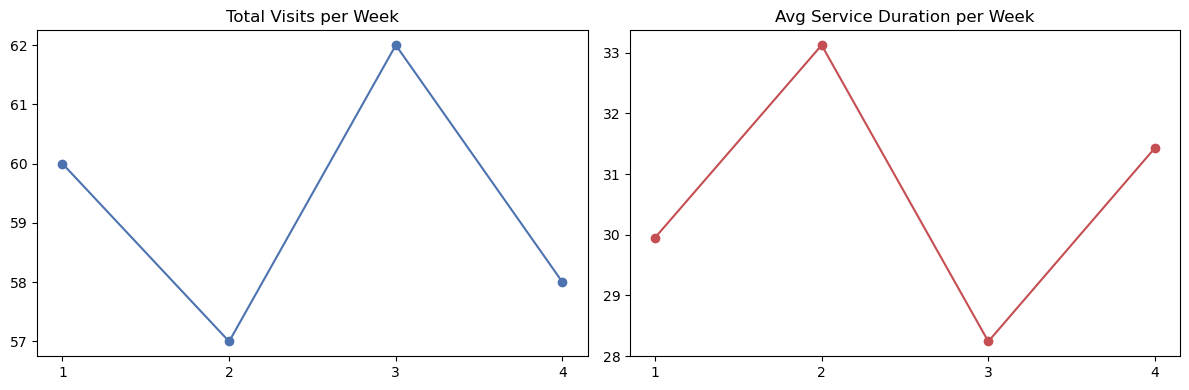

In [40]:
weekly = df.groupby('week_number').agg(
    total_visits=('date', 'count'),
    total_minutes=('duration_min', 'sum'),
    avg_duration=('duration_min', 'mean')
).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(12,4))
axes[0].plot(weekly['week_number'], weekly['total_visits'], marker='o', color='#4C72B0')
axes[0].set_title('Total Visits per Week')
axes[0].set_xticks(weekly['week_number'])

axes[1].plot(weekly['week_number'], weekly['avg_duration'], marker='o', color='#C44E52')
axes[1].set_title('Avg Service Duration per Week')
axes[1].set_xticks(weekly['week_number'])

plt.tight_layout()
plt.show()

In [41]:
weekly

,week_number,total_visits,total_minutes,avg_duration
0,1,60,1797,29.950000
1,2,57,1888,33.122807
2,3,62,1751,28.241935
3,4,58,1823,31.431034


In [42]:
pd.crosstab(df['week_number'], df['service_type'])

service_type,Beard Trim,Colour/Chemical,Haircut,Haircut + Beard,Kids Cut,Shave
week_number,,,,,,
1,10,1,21,14,7,7
2,10,5,30,9,1,2
3,13,1,36,7,2,3
4,9,1,23,16,6,3


**Observations (weekly trend)**
- Weekly visits: 60, 57, 62 and 58 (weeks 1 to 4).
- Total service minutes per week: 1797, 1888, 1751 and 1823.
- Average service duration per week: 29.95, 33.12, 28.24 and 31.43 min. Week 2 has the highest average and also the most Colour/Chemical services (5, against 1 in each of the other weeks).
- Visits per weekday are close from week to week in the Step 4 table (e.g. Saturday 14, 12, 14, 12; Tuesday 7, 7, 8, 7).